# Validation 1: is Kristofer's 0.99 alpha, or just holding assets that went up?

Kristofer's rule (EMA 10/100, long-only, stretch stop, on the 10 stocks and bonds) scores about **0.99** adjusted Sharpe. Simply **holding the same 10 assets long**, sized by volatility, scores about **0.97**. This notebook asks the question a Lynx researcher will ask in the first minute: **how much of the 0.99 is the rule, and how much is the 20-year rise in stocks and bonds?**

Method, in four checks:
1. Reproduce both numbers with Lynx's `evaluation.py`, using Kristofer's own signal code.
2. Isolate the rule's contribution: **rule minus always-long** is exactly the set of bets the rule makes *on top of* holding. Score that on its own.
3. Regress the rule's daily P&L on the always-long P&L: how much is explained by just holding?
4. Placebo: shift the rule's on/off pattern randomly in time (same time in market, same persistence). If random timing scores about the same, the timing has no skill.

In [1]:
import sys, warnings
from pathlib import Path
from importlib.machinery import SourceFileLoader
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "lynx_materials")]
import polars as pl, evaluation as ev

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; INK2, GRID, SURF = "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.grid": True,
    "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9, "legend.frameon": False})
pd.set_option("display.precision", 2, "display.width", 200)

# Kristofer's own code, loaded as is
K = SourceFileLoader("kris", str(ROOT / "research/kristofer/Kood mida vaadata")).load_module()
px = pd.read_csv(ROOT / "data/close_prices_insample.csv", parse_dates=["AsOfDate"], index_col=0)
SB = [c for c in px if c.endswith(("_stocks", "_bonds"))]
p = px[SB]
signal = K.build_signals(p)                                   # 1 = long, 0 = flat
vol = np.sqrt((p.diff() ** 2).rolling(K.VOL_WINDOW).mean())
START = p.index[K.WARMUP]                                     # score from day 400, like his script
ERAS = {"1995-02": ("1995", "2001"), "2002-09": ("2002", "2008"), "2009-16": ("2009", "2016")}

def to_pl(pos):
    pos = pos.replace([np.inf, -np.inf], np.nan).fillna(0.0).loc[START:].copy(); pos.index.name = "AsOfDate"
    return pl.from_pandas(pos.reset_index()).with_columns(pl.col("AsOfDate").cast(pl.Date))
PX = to_pl(p)

def score(pos):
    k = ev.calc_key_figures(to_pl(pos), PX, key_figures=["adjusted_sharpe", "sharpe", "av_holding", "position_bias", "returns"])
    r = k.pop("returns").to_pandas().set_index("AsOfDate")["returns"]
    for e, (a, b) in ERAS.items():
        x = r.loc[a:b].dropna(); k[e] = x.mean() / x.std() * np.sqrt(260)
    return k, r

POS = {
    "Kristofer rule": signal / vol,
    "always long (same 10, 1/vol)": 1 / vol,
    "rule minus always long (the timing only)": (signal - 1) / vol,
}
res, RET = {}, {}
for name, pos in POS.items():
    res[name], RET[name] = score(pos)
tab = pd.DataFrame(res).T[["adjusted_sharpe", "sharpe", *ERAS, "position_bias", "av_holding"]]
tab.columns = ["adj sharpe", "sharpe", *[f"sharpe {e}" for e in ERAS], "position bias", "holding d"]
print(f"time in market: {signal.loc[START:].mean().mean():.0%}")
tab

time in market: 62%


,adj sharpe,sharpe,sharpe 1995-02,sharpe 2002-09,sharpe 2009-16,position bias,holding d
Kristofer rule,1.00,1.23,1.14,1.13,1.41,1.0,46.95
"always long (same 10, 1/vol)",0.97,1.20,1.05,0.84,1.69,1.0,273.05
rule minus always long (the timing only),-0.33,-0.35,-0.37,0.08,-0.77,-1.0,30.71


**Read the table.** The first two rows are the 0.99 vs 0.97. The third row is the only part the rule itself adds: it's the rule's position minus the always-long position, so it's flat whenever the rule is invested and **short** whenever the rule steps aside. If the rule had real timing skill, this row would make money on its own.

In [2]:
r = pd.DataFrame(RET).loc[START:].dropna()
y, x = r["Kristofer rule"], r["always long (same 10, 1/vol)"]
beta = np.cov(y, x)[0, 1] / x.var()
resid = y - beta * x
n = len(resid)
reg = pd.Series({
    "correlation, rule vs always long": y.corr(x),
    "share of the rule's daily variance explained by holding (R²)": y.corr(x) ** 2,
    "beta to always long": beta,
    "Sharpe of what is left after removing holding (annual)": resid.mean() / resid.std() * np.sqrt(260),
    "t-stat of that leftover": resid.mean() / resid.std() * np.sqrt(n),
})
reg.to_frame("value").round(2)

,value
"correlation, rule vs always long",0.75
share of the rule's daily variance explained by holding (R²),0.56
beta to always long,0.59
Sharpe of what is left after removing holding (annual),0.51
t-stat of that leftover,2.29


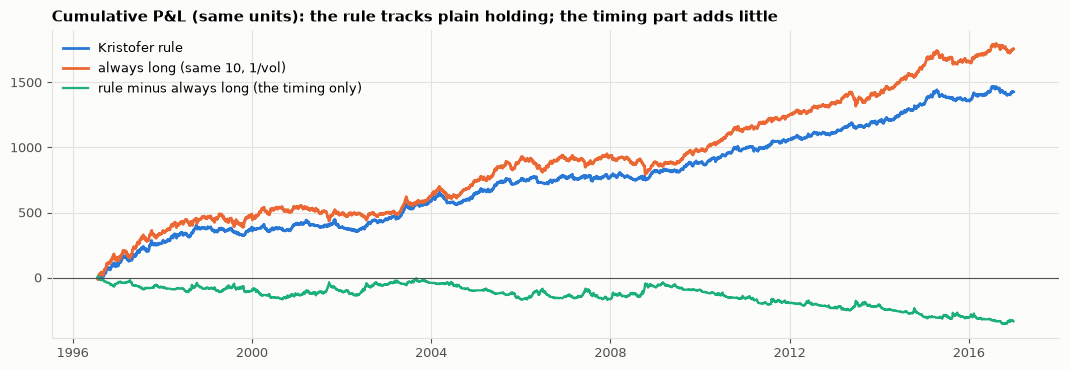

In [3]:
fig, ax = plt.subplots(figsize=(13, 4))
for i, (name, s) in enumerate(RET.items()):
    ax.plot(s.loc[START:].index, s.loc[START:].cumsum(), color=C[i], lw=2 if i < 2 else 1.6, label=name)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Cumulative P&L (same units): the rule tracks plain holding; the timing part adds little")
ax.legend(); plt.show()

### Placebo: random timing with the same habits

Each asset's on/off pattern is shifted in time by a random amount (wrapping around). That keeps exactly the same time in market and the same length of on and off spells, but breaks any link to what prices were doing. 200 draws.

real rule: 1.00 | random timing: median 0.86, 90% range 0.74 to 0.98
share of random-timing versions that beat the real rule: 2%


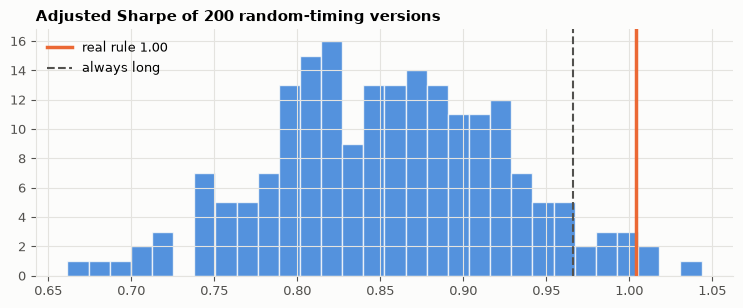

In [4]:
rng = np.random.default_rng(0)
sig = signal.values; T = len(sig); draws = []
for _ in range(200):
    sh = np.column_stack([np.roll(sig[:, j], rng.integers(250, T - 250)) for j in range(sig.shape[1])])
    draws.append(score(pd.DataFrame(sh, index=p.index, columns=SB) / vol)[0]["adjusted_sharpe"])
draws = np.array(draws)
real = res["Kristofer rule"]["adjusted_sharpe"]
print(f"real rule: {real:.2f} | random timing: median {np.median(draws):.2f}, 90% range {np.percentile(draws, 5):.2f} to {np.percentile(draws, 95):.2f}")
print(f"share of random-timing versions that beat the real rule: {(draws >= real).mean():.0%}")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(draws, bins=30, color=C[0], alpha=0.8, edgecolor=SURF)
ax.axvline(real, color=C[1], lw=2.5, label=f"real rule {real:.2f}")
ax.axvline(res["always long (same 10, 1/vol)"]["adjusted_sharpe"], color=INK2, lw=1.5, ls="--", label="always long")
ax.set_title("Adjusted Sharpe of 200 random-timing versions"); ax.legend(); plt.show()

In [5]:
pa = pd.DataFrame({
    "rule": [score(signal[[c]] / vol[[c]])[0]["adjusted_sharpe"] if False else np.nan for c in SB]}, index=SB)
def one(pos_col, c):
    k = ev.calc_key_figures(to_pl(pos_col), pl.from_pandas(p[[c]].reset_index()).with_columns(pl.col("AsOfDate").cast(pl.Date)),
                            key_figures=["sharpe"])
    return k["sharpe"]
pa = pd.DataFrame({c: {"rule": one(signal[[c]] / vol[[c]], c), "always long": one(1 / vol[[c]], c)} for c in SB}).T
pa["rule minus holding"] = pa["rule"] - pa["always long"]
pa["time in market"] = signal.loc[START:].mean()
print(f"assets where the rule beats holding: {(pa['rule minus holding'] > 0).sum()} of {len(pa)}")
pa.round(2)

assets where the rule beats holding: 6 of 10


,rule,always long,rule minus holding,time in market
ganymede_bonds,0.52,0.69,-0.17,0.69
ganymede_stocks,0.61,0.40,0.21,0.56
io_bonds,0.55,0.49,0.07,0.58
io_stocks,0.26,0.30,-0.04,0.64
titan_bonds,0.58,0.68,-0.10,0.65
titan_stocks,0.25,0.35,-0.09,0.63
callisto_bonds,0.78,0.72,0.06,0.71
callisto_stocks,0.38,0.16,0.22,0.49
europa_bonds,0.98,0.93,0.05,0.65
europa_stocks,0.47,0.43,0.04,0.60


## Verdict: mostly drift, plus a small real crash filter

| Check | Result | Meaning |
|---|---|---|
| Rule vs plain holding | **1.00 vs 0.97** | Almost all of the score is available by just holding the same 10 assets |
| Position bias | **1.00** for both | 100% long all the time; never short |
| Timing on its own (rule minus holding) | **−0.33** | Stepping out of the market loses money on average: the assets keep rising while the rule is flat |
| Daily P&L explained by holding | **R² 0.56**, correlation 0.75 | Most of the day-to-day P&L is plain holding |
| Leftover after removing holding | **Sharpe 0.51, t ≈ 2.3** | There is something extra: the rule holds less (62% of the time) but loses less in crashes |
| Random timing, same time in market | median **0.86**; real rule beats **98%** of 200 draws | The *when* to step aside is better than chance |
| By era (Sharpe) | 2002–09: rule **1.13** vs holding **0.84**; 2009–16: rule **1.41** vs holding **1.69** | It helps in the 2008 crash, costs money in a calm bull market |

**In one line:** the 0.99 is mostly the 20-year rise in stocks and bonds; the rule itself adds a modest, real crash filter (it beats random timing), but it isn't a return source.

## Why it matters
- Lynx's  reports  exactly to catch this, and their instructions say they judge "a mechanism that would plausibly work in practice". "Stocks and bonds went up for 20 years" is a market view, not a mechanism. If the test period has rising rates or a bear market, the 0.97 part disappears.
- Any blend that includes the rule inherits a long tilt (the Dual-Engine's position bias is about +0.5). Part of its 1.03 is that tilt.

## What to do with it
- **Don't present the 0.99 as alpha.** Present it as a long bias with a crash filter, which is honest and still interesting (it beats random timing).
- **Score every candidate against always-long on the same assets**, and show position bias next to the Sharpe. That's the bar Lynx will use in their heads.
- **If we keep a long tilt on purpose, say so and size it deliberately**, rather than letting it hide inside a blend.